# 05 — Model selection under recording-level validation

**Replication of:** *Presence-absence estimation in audio recordings of tropical frog communities*
(Estrella Terneux, Nicolalde, Nicolalde & Merino-Viteri, arXiv:1901.02495), Sections **4.1 and 4.2** (choice of features and of model order)

## 1. Objective

The article picks its final configuration from its own experiments: **20 m-FCC** with **64 Gaussians** (Sections 4.1 and 4.2).
Notebooks 03 and 04 ran those experiments on the recovered corpus and found three things that make the article's choice unsafe to copy:

- most validation calls come from a recording that also supplied training calls (notebook 03);
- PLP-RASTA beats the other features by a wide margin, but how much depends on how the RASTA filter starts (notebook 04);
- the best number of Gaussians is small, not 64 (notebooks 03 and 04).

This notebook makes the choice again, **under a validation that keeps whole recordings apart**: a recording is either in training or in
validation, for every species. It is the question the deployed detector faces, since the pond recordings are new recordings made with other
equipment (`[PAPER]` Section 4.3).

**Stage A** compares the feature sets at 12 seconds of training per species. **Stage B** then varies the training duration (6, 12, 18 seconds) and the
number of Gaussians (2 to 64) for the winner and for the other way of starting the RASTA filter, so that the choice between them is made on evidence.
The result is a configuration file that the detector stage reads.

*This is not the article's protocol.* The article does not say whether segments of one recording may fall on both sides of its split, and its numbers are
reproduced by notebooks 03 and 04. Here the aim is to choose, not to reproduce.

### What the article does not specify

How the article's PLP-RASTA started its filter, how its MFCC were built, and how the training and validation sets were drawn. All three are
reconstructions or decisions made here and stated where they are made.

## 2. Setup

**What this section asks, and why it matters.** The notebook reads the per-call features of notebook 04 and, for two PLP variants that notebook did not
store, recomputes them from the audio. The audio is located through `.env`.

In [1]:
# Every dependency, the display options, the dataset location from .env and the artefacts of notebooks 02 and 04.
import json
import os
from pathlib import Path

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from dotenv import load_dotenv
from joblib import Parallel, delayed

from frog_presence import features as F
from frog_presence.audio import index_wavs, read_call_audio
from frog_presence.gmm import (
    CallCorpus, build_global_recording_split, build_split, evaluate_models, fit_species_models,
)

sns.set_theme(style="ticks")
pd.set_option("display.width", 180)
pd.set_option("display.max_rows", 140)
pd.set_option("display.max_columns", 80)

CWD = Path.cwd().resolve()
REPO_ROOT = CWD.parent if CWD.name == "notebooks" else CWD
PROCESSED_DIR = REPO_ROOT / "data" / "processed"
CALLS_PATH = PROCESSED_DIR / "calls.csv"
CACHE_PATH = PROCESSED_DIR / "feature_comparison" / "call_feature_sets.joblib"
RESULTS_DIR = PROCESSED_DIR / "robust_model_selection"
RESULTS_DIR.mkdir(parents=True, exist_ok=True)

for path in (CALLS_PATH, CACHE_PATH):
    if not path.exists():
        raise FileNotFoundError(f"Missing {path.name}. Run notebooks 02 and 04 first.")

load_dotenv(REPO_ROOT / ".env")
mendeley_value = os.environ.get("MENDELEY_CALL_DIR")
if not mendeley_value:
    raise RuntimeError("MENDELEY_CALL_DIR is not set. Copy .env.example to .env and fill in the paths.")
MENDELEY_CALL_DIR = Path(mendeley_value).expanduser()
if not MENDELEY_CALL_DIR.is_dir():
    raise FileNotFoundError(f"The folder configured as MENDELEY_CALL_DIR ({MENDELEY_CALL_DIR.name}) does not exist.")

# Only folder names are printed: the full paths are personal to whoever runs the notebook.
print("Dataset used   : MENDELEY_CALL_DIR ->", MENDELEY_CALL_DIR.name)
print("Results written:", RESULTS_DIR.relative_to(REPO_ROOT).as_posix())
print("CPU workers    :", os.cpu_count())

Dataset used   : MENDELEY_CALL_DIR -> mendeley
Results written: data/processed/robust_model_selection
CPU workers    : 32


## 3. Load the call features and build the two PLP variants

**What this section asks, and why it matters.** Notebook 04 stored four feature sets per call. Its PLP-RASTA is the **zero-start** one (the RASTA filter starts
each call from silence), and notebook 04 showed that this start accounts for much of that feature's lead under the article's protocol. To choose between PLP-RASTA
as built, PLP-RASTA with a **steady-state start**, and plain PLP, the last two are recomputed here from the same call intervals.

The stored cache is checked against the extractor first, so the zero-start features are known to be what `frog_presence.features` produces.

In [2]:
# Load the call table and the stored per-call features, and check they describe the same calls.
calls = pd.read_csv(CALLS_PATH).reset_index(drop=True)
calls["call_id"] = [f"call_{i:04d}" for i in range(len(calls))]
CALL_FEATURES = joblib.load(CACHE_PATH)
assert set(CALL_FEATURES) == set(calls.call_id), "the feature cache and calls.csv describe different calls"

STORED_NAMES = ("12_MFCC", "20_MFCC", "20_PLP_RASTA", "20_mFCC")
for call_id, frames in zip(calls.call_id, calls.frames):
    for name in STORED_NAMES:
        X = CALL_FEATURES[call_id][name]
        assert len(X) == frames and np.isfinite(X).all(), f"{call_id} {name}"

print("calls                :", len(calls))
print("stored feature sets  :", STORED_NAMES)
print("every stored matrix has the stored frame count and finite values: True")

calls                : 1461
stored feature sets  : ('12_MFCC', '20_MFCC', '20_PLP_RASTA', '20_mFCC')
every stored matrix has the stored frame count and finite values: True


In [3]:
# Recompute the steady-start and no-RASTA PLP from the audio, and check the stored zero-start PLP against the extractor.
WAVS = index_wavs(MENDELEY_CALL_DIR)
assert set(calls.wav.str.lower()) <= set(WAVS), "a recording named in calls.csv is not on disk"


def plp_variants(wav, start, end, rate):
    """The two PLP variants of one call, plus the zero-start version for checking."""
    audio, sr = read_call_audio(WAVS[wav.lower()], start, end, rate)
    return {"PLP_steady": F.plp_rasta(audio, sr, rasta="steady"),
            "PLP_no_rasta": F.plp_rasta(audio, sr, rasta=None),
            "zero": F.plp_rasta(audio, sr, rasta="zero")}


extracted = Parallel(n_jobs=-1)(
    delayed(plp_variants)(r.wav, r.start, r.end, r.rate) for r in calls.itertuples(index=False))

VARIANTS = {cid: {k: v for k, v in e.items() if k != "zero"} for cid, e in zip(calls.call_id, extracted)}
worst = max(float(np.abs(e["zero"] - CALL_FEATURES[cid]["20_PLP_RASTA"]).max()) for cid, e in zip(calls.call_id, extracted))
print("calls processed:", len(extracted))
print("largest difference between the stored zero-start PLP and the extractor:", f"{worst:.1e}")
assert worst < 1e-9

calls processed: 1461
largest difference between the stored zero-start PLP and the extractor: 6.4e-14


`[OBSERVED]` All **1461 calls** have the four stored feature sets with the stored frame counts and finite values. The zero-start PLP-RASTA
recomputed by the extractor differs from the stored one by at most **6.4e-14**, so the stored feature is exactly what `frog_presence.features` produces, and the two PLP variants
built here differ from it only in the RASTA step.

## 4. Species and recordings

**What this section asks, and why it matters.** A validation that keeps recordings apart is only as informative as the number of recordings each species has: a
species with three recordings can have at most two held out. The inventory also shows which recordings carry more than one species, which decides how the split has to be built.

In [4]:
# Fix the grid, derive the usable species as in notebook 03, and count the recordings each species has.
TARGETS = (6, 12, 18)
N_COMPONENTS_GRID = (2, 4, 8, 16, 32, 64)
N_REPEATS = 10
BASE_SEED = 20260814
STAGE_A_SECONDS = 12

species_inventory = (calls.groupby(["code", "species"], as_index=False)
                     .agg(calls=("call_id", "size"), seconds=("seconds", "sum"), recordings=("wav", "nunique")))
USABLE_CODES = tuple(species_inventory.loc[species_inventory.seconds > max(TARGETS), "code"])
display(species_inventory.assign(used=species_inventory.code.isin(USABLE_CODES)).round(2))

species_per_wav = calls.groupby("wav").code.nunique()
shared = species_per_wav[species_per_wav > 1]
print("recordings in the corpus                 :", calls.wav.nunique())
print("recordings that carry more than one species:", len(shared))
print(calls[calls.wav.isin(shared.index)].groupby("wav").code.agg(lambda c: sorted(set(c))).to_string())

,code,species,calls,seconds,recordings,used
0,f01,Boana alfaroi,98,44.72,5,True
1,f02,Dendropsophus bifurcus,99,41.72,10,True
2,f03,Boana cinerascens,169,102.58,8,True
3,f04,Pristimantis conspicillatus,186,77.94,9,True
4,f05,Leptodactylus discodactylus,340,114.36,3,True
5,f06,Osteocephalus fuscifacies,54,24.94,5,True
6,f07,Boana lanciformis,101,57.84,7,True
7,f08,Rhinella margaritifera,96,102.66,7,True
8,f09,Dendropsophus parviceps,2,1.18,1,False
9,f10,Engystomops petersi,316,134.00,12,True


recordings in the corpus                 : 66
recordings that carry more than one species: 1
wav
D-bifircus-D-parviceps-LS100120.WAV    [f02, f09]


`[OBSERVED]` The corpus has **66 recordings**, and **one** carries more than one species: `D-bifircus-D-parviceps-LS100120.WAV`, with `f02` and `f09`. `f09` is not modelled, so within the nine
usable species no recording is shared, but the split is still built globally.

`[OBSERVED]` The number of recordings per species is small: `f05` has **3**, `f01` and `f06` have 5, and `f10` has 12. A species with three recordings can have at most two held out,
so its held-out error rests on very few independent recordings.

## 5. Recording-level splits

**What this section asks, and why it matters.** Every comparison below uses the same ten splits per training duration, so that feature sets and model orders are
compared on the same recordings. The splits have to be valid (no recording on both sides, every species with enough training material and some validation calls) and
reproducible.

*Decisions, not stated in the article:*

- the assignment is **global**: a recording in training is training material for every species it contains, so no recording is ever on both sides for any species;
- recordings are added in a random order until every species has reached the target, and of many such assignments the one with the **smallest overshoot** is kept, so the
  durations 6, 12 and 18 seconds are *minimum* targets and actual training is longer for some species.

In [5]:
# Build the 30 splits (3 durations x 10 repeats), and one corpus per feature set.
base_calls = calls[["code", "species", "wav", "seconds", "frames"]]


def corpus_from(matrices_by_call: dict, name: str) -> CallCorpus:
    """A corpus of one feature set, with the frames of the calls stacked in call order."""
    return CallCorpus(np.vstack([matrices_by_call[cid][name] for cid in calls.call_id]), base_calls)


FEATURE_LABELS = {
    "12_MFCC": "12 MFCC", "20_MFCC": "20 MFCC", "20_mFCC": "20 m-FCC",
    "20_PLP_RASTA": "PLP-RASTA, zero start", "PLP_steady": "PLP-RASTA, steady start", "PLP_no_rasta": "PLP, no RASTA",
}
CORPORA = {**{n: corpus_from(CALL_FEATURES, n) for n in STORED_NAMES},
           **{n: corpus_from(VARIANTS, n) for n in ("PLP_steady", "PLP_no_rasta")}}
assert all(c.calls.call_id.equals(calls.call_id) for c in CORPORA.values())

reference_calls = CORPORA["20_PLP_RASTA"].calls
SPLITS = {(target, repeat): build_global_recording_split(reference_calls, USABLE_CODES, target, repeat, BASE_SEED)
          for target in TARGETS for repeat in range(N_REPEATS)}

audit = pd.concat([s[2].assign(repeat=r, target=t) for (t, r), s in SPLITS.items()], ignore_index=True)
by_call = reference_calls.set_index("call_id").wav.str.lower()
train_sets = {(t, r): frozenset(by_call.loc[[c for ids in s[0].values() for c in ids]]) for (t, r), s in SPLITS.items()}
unique_sets = pd.Series({t: len({train_sets[(t, r)] for r in range(N_REPEATS)}) for t in TARGETS}, name="distinct training sets of 10")

for (t, r), (train, validation, _) in SPLITS.items():
    train_wavs = set(by_call.loc[[c for ids in train.values() for c in ids]])
    validation_wavs = set(by_call.loc[[c for ids in validation.values() for c in ids]])
    assert not train_wavs & validation_wavs, f"a recording is on both sides ({t} s, repeat {r})"
print("splits built:", len(SPLITS), "| a recording on both sides in any of them: False")
print("\n", unique_sets.to_string())

display(audit.groupby(["target", "code"]).agg(
    actual_seconds_mean=("training_seconds_actual", "mean"), actual_seconds_max=("training_seconds_actual", "max"),
    train_recordings=("n_train_recordings", "mean"), validation_recordings=("n_validation_recordings", "mean"),
    validation_calls=("n_validation_calls", "mean")).round(2).unstack("target"))

splits built: 30 | a recording on both sides in any of them: False

 6     10
12    10
18    10


actual_seconds_mean               actual_seconds_max               train_recordings           validation_recordings            validation_calls              
target                  6      12     18                 6      12     18               6    12   18                    6     12   18               6      12     18
code                                                                                                                                                                
f01                   8.74  17.18  19.00              10.22  18.40  19.42              1.0  2.0  2.0                   4.0   3.0  3.0             78.7   59.9   57.2
f02                   8.08  13.33  19.43              13.58  15.66  21.30              2.2  4.1  4.6                   7.8   5.9  5.4             79.8   67.7   52.6
f03                   8.50  13.13  20.52              15.50  14.18  25.44              1.2  1.1  2.0                   6.8   6.9  6.0            153.8  148.0  135.6
f04                   9.47  13.65  20.12              13.84  16.52  23.94              1.2  1.3  2.6                   7.8   7.7  6.4            162.4  153.9  137.6
f05                   7.52  47.56  47.56               7.52  47.56  47.56              1.0  1.0  1.0                   2.0   2.0  2.0            318.0  205.0  205.0
f06                   7.03  14.36  18.72               8.70  17.84  20.54              1.2  2.5  3.8                   3.8   2.5  1.2             38.2   22.6   12.9
f07                   7.39  13.86  20.92               9.34  16.26  23.58              1.0  1.6  2.8                   6.0   5.4  4.2             87.6   78.3   64.5
f08                  12.01  14.56  21.78              15.28  15.28  27.06              1.0  1.6  2.1                   6.0   5.4  4.9             82.9   80.0   72.3
f10                   7.45  14.54  22.28               8.32  16.02  27.26              1.1  1.2  2.5                  10.9  10.8  9.5            298.4  282.7  264.2

`[OBSERVED]` All **30 splits** are valid: no recording is on both sides in any of them, and each duration has **10 distinct** training sets.

`[OBSERVED]` The durations are minimum targets and the training really used is often longer. `f05` trains on **47.56 seconds** at both the 12 and the 18-second minimum, because a single recording
holds that much, and has 1 training and 2 validation recordings. At the 6-second minimum `f08` trains on 12.01 seconds on average. The validation material is thin for some species: `f06`
has 1.2 validation recordings on average at the 18-second minimum.

## 6. Why the validation has to keep recordings apart

**What this section asks, and why it matters.** Notebooks 03 and 04 measured how often a validation call shares its recording with training. The consequence for the
number that drives every choice is shown directly here: the same features, the same model orders and the same seeds, with the calls split at random (the article's protocol) and with
recordings kept apart. Only the way the split is drawn changes.

The training amounts are not identical, since whole recordings are added in the second case, so the comparison also reports the training seconds actually used.

In [6]:
# Fit and score one (feature set, protocol, duration, repeat) cell for every model order, in parallel.
def run_cell(corpus, feature, protocol, target_seconds, repeat, orders, split):
    """Per-species results of one split of one feature set, for each number of components."""
    train, validation, summary = split
    blocks = []
    for n_components in orders:
        models = fit_species_models(corpus, train, n_components, target_seconds, repeat, BASE_SEED)
        per_species, _, _ = evaluate_models(models, corpus, validation, summary, n_components, target_seconds, repeat)
        per_species["converged"] = per_species.code.map({c: bool(m.converged_) for c, m in models.items()})
        per_species["feature"], per_species["protocol"] = feature, protocol
        blocks.append(per_species)
    return pd.concat(blocks, ignore_index=True)


def split_for(corpus, protocol, target, repeat):
    if protocol == "call":
        return build_split(corpus.calls, USABLE_CODES, target, repeat, BASE_SEED)
    return SPLITS[(target, repeat)]


def run_grid(features, protocol, targets, orders=N_COMPONENTS_GRID, repeats=N_REPEATS):
    """Run every (feature set, duration, repeat) cell in parallel and stack the per-species tables."""
    jobs = [(f, t, r) for f in features for t in targets for r in range(repeats)]
    blocks = Parallel(n_jobs=-1)(
        delayed(run_cell)(CORPORA[f], f, protocol, t, r, orders, split_for(CORPORA[f], protocol, t, r)) for f, t, r in jobs)
    return pd.concat(blocks, ignore_index=True)


def wer_by_repeat(per_species: pd.DataFrame) -> pd.DataFrame:
    """Weighted error rate (%) of each condition: the mean of the per-species errors."""
    keys = ["feature", "protocol", "training_seconds_target", "n_components", "repeat"]
    return per_species.groupby(keys, as_index=False).error_rate.mean().assign(
        WER_percent=lambda t: t.error_rate * 100).drop(columns="error_rate")


def summarise(wer: pd.DataFrame, keys) -> pd.DataFrame:
    """Mean, standard deviation, standard error, minimum and maximum of the WER over the repeats."""
    out = wer.groupby(keys, as_index=False).WER_percent.agg(
        WER_mean="mean", WER_std="std", WER_min="min", WER_max="max", repeats="size")
    out["WER_se"] = out.WER_std / np.sqrt(out.repeats)
    return out


LEAK_FEATURES = ("20_PLP_RASTA", "20_mFCC")
per_species_leak = pd.concat([run_grid(LEAK_FEATURES, "call", (STAGE_A_SECONDS,)),
                              run_grid(LEAK_FEATURES, "recording", (STAGE_A_SECONDS,))], ignore_index=True)
wer_leak = wer_by_repeat(per_species_leak)
assert len(wer_leak) == 2 * len(LEAK_FEATURES) * len(N_COMPONENTS_GRID) * N_REPEATS

leak_table = (summarise(wer_leak, ["feature", "protocol", "n_components"])
              .pivot(index=["feature", "protocol"], columns="n_components", values="WER_mean"))
leak_table.index = [(FEATURE_LABELS[f], "calls split at random" if p == "call" else "recordings kept apart") for f, p in leak_table.index]
print("Mean WER (%) at 12 s (minimum target when recordings are kept apart), by number of Gaussians:")
display(leak_table.round(3))

used = per_species_leak[per_species_leak.n_components == N_COMPONENTS_GRID[0]]
print("mean training seconds actually used per species, by protocol:")
print(used.groupby("protocol").training_seconds_actual.mean().round(2).to_string())

Mean WER (%) at 12 s (minimum target when recordings are kept apart), by number of Gaussians:


n_components,2,4,8,16,32,64
"(PLP-RASTA, zero start, calls split at random)",2.370,0.663,0.361,0.285,0.235,0.335
"(PLP-RASTA, zero start, recordings kept apart)",20.955,16.229,18.648,22.436,27.377,31.871
"(20 m-FCC, calls split at random)",2.069,0.748,0.831,1.257,1.779,1.528
"(20 m-FCC, recordings kept apart)",38.975,41.771,42.247,44.386,48.576,46.451


mean training seconds actually used per species, by protocol:
protocol
call         12.27
recording    18.02


`[OBSERVED]` With the same features, model orders and seeds, keeping recordings apart changes the error by an order of magnitude. For PLP-RASTA (zero start) the error is
**0.235 % to 2.370 %** when calls are split at random and **16.229 % to 31.871 %** when recordings are kept apart. For m-FCC it is 0.748 % to 2.069 % against **38.975 % to 48.576 %**.

`[OBSERVED]` The recording-level protocol is not penalised by a shortage of training: it uses 18.02 seconds per species on average against 12.27 for the call-level one.

`[OBSERVED]` The shape of the curve also changes. With calls split at random the error is lowest at M=32 for PLP-RASTA; with recordings kept apart it is lowest at **M=4** (16.229 %) and
rises to 31.871 % at M=64.

`[INFERENCE]` The article's protocol measures how well a model recognises species in recordings it has partly heard, and the figures it produces, and the model order they favour, say little about
the unseen recordings of the testing stage. Every choice below is made under the second protocol.

## 7. Stage A: which feature set, at 12 seconds

**What this section asks, and why it matters.** Six feature sets, six model orders and ten recording-level splits give 360 conditions. All feature sets share the same splits and the same
random starts, so only the features differ.

The three PLP variants are the controls of notebook 04: PLP-RASTA as built (zero start), with a steady-state start, and without RASTA. The recording-level protocol is where RASTA is supposed to
matter, because it removes a constant colouration that a held-out recording would carry differently.

conditions: 360 of 360
fits      : 3240 | converged: 3240

Mean WER (%) with recordings kept apart, 12 s minimum, by number of Gaussians:


n_components,2,4,8,16,32,64
12 MFCC,40.363,44.053,47.876,50.042,48.956,47.613
20 MFCC,41.303,45.020,45.700,49.492,46.259,46.856
20 m-FCC,38.975,41.771,42.247,44.386,48.576,46.451
"PLP-RASTA, zero start",20.955,16.229,18.648,22.436,27.377,31.871
"PLP-RASTA, steady start",19.067,17.961,21.654,28.403,32.926,36.885
"PLP, no RASTA",38.576,40.222,41.158,43.790,45.871,45.289


Standard deviation over the ten splits:


n_components,2,4,8,16,32,64
12 MFCC,4.58,4.98,5.40,3.81,3.34,4.74
20 MFCC,5.11,6.25,4.81,4.22,4.32,4.44
20 m-FCC,6.21,5.94,6.18,7.59,3.53,3.28
"PLP-RASTA, zero start",3.89,2.74,4.36,6.02,6.31,6.71
"PLP-RASTA, steady start",3.27,4.22,4.06,6.05,7.23,7.50
"PLP, no RASTA",4.95,4.51,6.29,3.42,2.48,3.01


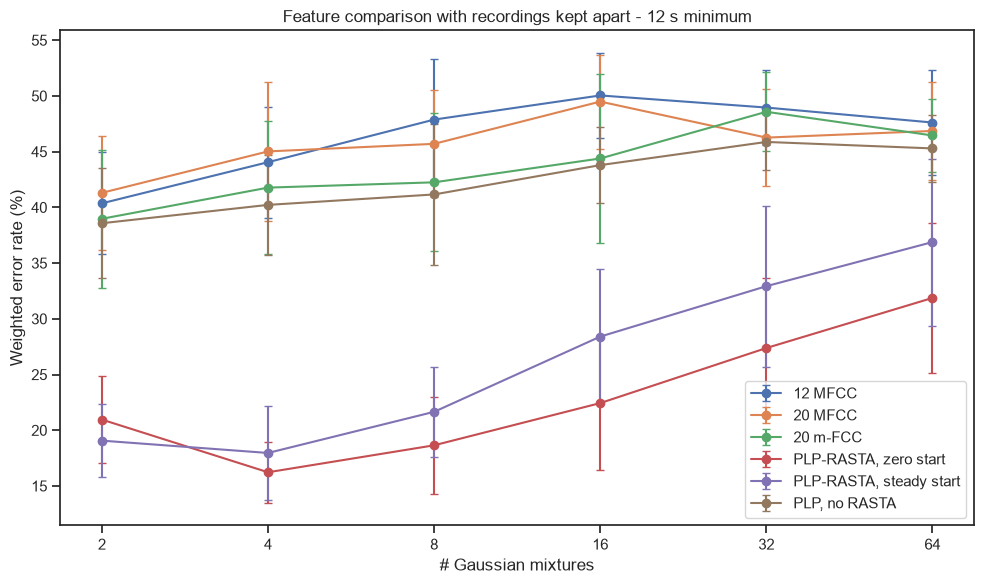

In [7]:
# Run Stage A: every feature set at 12 s, recording-level splits, all model orders and repeats.
STAGE_A_FEATURES = ("12_MFCC", "20_MFCC", "20_mFCC", "20_PLP_RASTA", "PLP_steady", "PLP_no_rasta")
per_species_a = run_grid(STAGE_A_FEATURES, "recording", (STAGE_A_SECONDS,))
wer_a = wer_by_repeat(per_species_a)

expected = len(STAGE_A_FEATURES) * len(N_COMPONENTS_GRID) * N_REPEATS
assert len(wer_a) == expected and per_species_a.error_rate.between(0, 1).all()
print("conditions:", len(wer_a), "of", expected)
print("fits      :", len(per_species_a), "| converged:", int(per_species_a.converged.sum()))

summary_a = summarise(wer_a, ["feature", "n_components"])
table_a = summary_a.pivot(index="feature", columns="n_components", values="WER_mean").loc[list(STAGE_A_FEATURES)]
std_a = summary_a.pivot(index="feature", columns="n_components", values="WER_std").loc[list(STAGE_A_FEATURES)]
table_a.index = std_a.index = [FEATURE_LABELS[f] for f in table_a.index]
print("\nMean WER (%) with recordings kept apart, 12 s minimum, by number of Gaussians:")
display(table_a.round(3))
print("Standard deviation over the ten splits:")
display(std_a.round(2))

fig, ax = plt.subplots(figsize=(10, 6))
for name, row in table_a.iterrows():
    ax.errorbar(N_COMPONENTS_GRID, row.to_numpy(), yerr=std_a.loc[name].to_numpy(), marker="o", capsize=3, label=name)
ax.set_xscale("log", base=2)
ax.set_xticks(N_COMPONENTS_GRID)
ax.set_xticklabels([str(m) for m in N_COMPONENTS_GRID])
ax.set(title="Feature comparison with recordings kept apart - 12 s minimum", xlabel="# Gaussian mixtures",
       ylabel="Weighted error rate (%)")
ax.legend()
plt.tight_layout()
plt.show()

`[OBSERVED]` All **3240 fits converged**.

`[OBSERVED]` The four features without RASTA are far behind: their best mean WER lies between **38.576 % and 41.303 %**, against **16.229 %** for PLP-RASTA as built (at M=4) and **17.961 %** with a steady start
(also at M=4). Plain PLP, which differs from PLP-RASTA only by the temporal filter, is at 38.576 % at its best. m-FCC does no better than the standard MFCC here (38.975 % against 40.363 % for 12 MFCC and 41.303 % for 20 MFCC).

`[OBSERVED]` The four feature sets without RASTA are at their best at **M=2** and higher at every larger order. The two RASTA versions are at their best at M=4 and rise beyond it: the as-built PLP-RASTA goes from 16.229 % at M=4 to 31.871 % at M=64.

`[PAPER]` The article ranks m-FCC first. It does not rank first under this protocol, nor under the article's own protocol in notebook 04.

## 8. Paired comparison of the feature sets

**What this section asks, and why it matters.** The ten splits are shared by all feature sets, so each feature can be compared with the best one split by split. A difference is
*feature minus the as-built PLP-RASTA*, in percentage points, so a positive value means the as-built PLP-RASTA is better.

The ten splits are drawn from the same 66 recordings and overlap, so they are **not independent**. The spread of the paired differences describes how much the answer moves from one split to the
next, not a confidence interval, and no p-value is given.

In [8]:
# Paired differences against the as-built PLP-RASTA on identical splits, for every feature set and model order.
wide = wer_a.pivot_table(index=["n_components", "repeat"], columns="feature", values="WER_percent")
REFERENCE = "20_PLP_RASTA"
rows = []
for name in STAGE_A_FEATURES:
    if name == REFERENCE:
        continue
    diff = (wide[name] - wide[REFERENCE]).unstack("repeat")
    for M in N_COMPONENTS_GRID:
        d = diff.loc[M]
        rows.append({"feature": FEATURE_LABELS[name], "M": M, "mean_diff_pp": d.mean(), "std_diff_pp": d.std(ddof=1),
                     "reference_better_in": int((d > 0).sum())})
paired_a = pd.DataFrame(rows)

order = [FEATURE_LABELS[n] for n in STAGE_A_FEATURES if n != REFERENCE]
print("mean paired difference (percentage points), feature minus as-built PLP-RASTA:")
display(paired_a.pivot(index="feature", columns="M", values="mean_diff_pp").loc[order].round(2))
print("splits (of", N_REPEATS, ") in which the as-built PLP-RASTA is better:")
display(paired_a.pivot(index="feature", columns="M", values="reference_better_in").loc[order])
print("standard deviation of the paired differences (pp):")
display(paired_a.pivot(index="feature", columns="M", values="std_diff_pp").loc[order].round(2))

mean paired difference (percentage points), feature minus as-built PLP-RASTA:


M,2,4,8,16,32,64
feature,,,,,,
12 MFCC,19.41,27.82,29.23,27.61,21.58,15.74
20 MFCC,20.35,28.79,27.05,27.06,18.88,14.99
20 m-FCC,18.02,25.54,23.60,21.95,21.20,14.58
"PLP-RASTA, steady start",-1.89,1.73,3.01,5.97,5.55,5.01
"PLP, no RASTA",17.62,23.99,22.51,21.35,18.49,13.42


splits (of 10 ) in which the as-built PLP-RASTA is better:


M,2,4,8,16,32,64
feature,,,,,,
12 MFCC,10,10,10,10,10,10
20 MFCC,10,10,10,10,10,10
20 m-FCC,10,10,10,10,10,10
"PLP-RASTA, steady start",2,7,9,10,10,10
"PLP, no RASTA",10,10,10,10,10,10


standard deviation of the paired differences (pp):


M,2,4,8,16,32,64
feature,,,,,,
12 MFCC,6.14,6.22,5.50,6.50,6.55,8.33
20 MFCC,5.29,6.87,4.77,6.04,8.55,7.43
20 m-FCC,7.27,6.25,7.23,6.68,6.73,8.63
"PLP-RASTA, steady start",2.04,3.44,3.84,2.57,2.36,2.92
"PLP, no RASTA",6.61,4.64,7.01,6.99,6.35,7.48


`[OBSERVED]` Against each of the four feature sets without RASTA the as-built PLP-RASTA is better in **10 of 10 splits at every model order**, by 13.42 to 29.23 percentage points on average.

`[OBSERVED]` The steady-start version is closer. At M=2 it is better by 1.89 points (the as-built one is better in 2 of 10 splits). At **M=4** the as-built one is better by 1.73 points with a spread of 3.44, and in 7 of 10 splits. From M=16 up the as-built one is better by 5.97, 5.55 and 5.01 points in 10 of 10 splits.

`[INFERENCE]` The advantage of RASTA over the other features is beyond doubt at every model order. Between the two ways of starting the filter, the data separate them only above M=4.

## 9. Choosing the feature

**What this section asks, and why it matters.** A rule fixed before looking at the numbers: for each feature set take its **best mean WER over the six model orders**, and
the winner is the feature set with the lowest of those. Because the as-built PLP-RASTA and the steady-start version are close, Stage B is run for the winner **and** for the other RASTA start, so
that the choice of start can be examined at every duration and model order and not decided from one column.

In [9]:
# Apply the selection rule to Stage A, and decide which features go to Stage B.
best_per_feature = (summary_a.sort_values(["feature", "WER_mean"]).groupby("feature", as_index=False).first()
                    .sort_values("WER_mean")[["feature", "n_components", "WER_mean", "WER_std", "WER_se"]])
display(best_per_feature.assign(feature=best_per_feature.feature.map(FEATURE_LABELS)).round(3))

ROBUST_FEATURE = str(best_per_feature.iloc[0].feature)
OTHER_START = {"20_PLP_RASTA": "PLP_steady", "PLP_steady": "20_PLP_RASTA"}.get(ROBUST_FEATURE)
STAGE_B_FEATURES = tuple(f for f in (ROBUST_FEATURE, OTHER_START) if f)
print("winner of Stage A       :", FEATURE_LABELS[ROBUST_FEATURE])
print("carried to Stage B      :", [FEATURE_LABELS[f] for f in STAGE_B_FEATURES])

,feature,n_components,WER_mean,WER_std,WER_se
2,"PLP-RASTA, zero start",4,16.229,2.738,0.866
5,"PLP-RASTA, steady start",4,17.961,4.222,1.335
4,"PLP, no RASTA",2,38.576,4.952,1.566
3,20 m-FCC,2,38.975,6.208,1.963
0,12 MFCC,2,40.363,4.583,1.449
1,20 MFCC,2,41.303,5.108,1.615


winner of Stage A       : PLP-RASTA, zero start
carried to Stage B      : ['PLP-RASTA, zero start', 'PLP-RASTA, steady start']


`[OBSERVED]` Applying the rule fixed beforehand, the winner is **PLP-RASTA with the as-built (zero) start**, with its best mean WER of 16.229 % at M=4, ahead of the steady-start version with 17.961 %.
Both are carried to Stage B.

## 10. Stage B: training duration and number of Gaussians

**What this section asks, and why it matters.** For the carried features the grid is completed with the 6 and 18-second splits; the 12-second results are those of Stage A, not refitted.
The training duration is a *minimum* here, so the table is read together with the training amount each duration really involves, which is shown in the next section.

conditions: 360 | fits: 3240 | converged: 3240

PLP-RASTA, zero start - mean WER (%) by training minimum (rows) and number of Gaussians (columns):


n_components,2,4,8,16,32,64
training_seconds_target,,,,,,
6,29.334,23.012,27.465,29.940,31.137,33.880
12,20.955,16.229,18.648,22.436,27.377,31.871
18,15.113,8.552,9.991,8.073,10.013,11.679



PLP-RASTA, steady start - mean WER (%) by training minimum (rows) and number of Gaussians (columns):


n_components,2,4,8,16,32,64
training_seconds_target,,,,,,
6,26.271,25.359,28.638,30.331,32.058,33.860
12,19.067,17.961,21.654,28.403,32.926,36.885
18,11.725,9.971,11.968,12.045,13.625,18.768


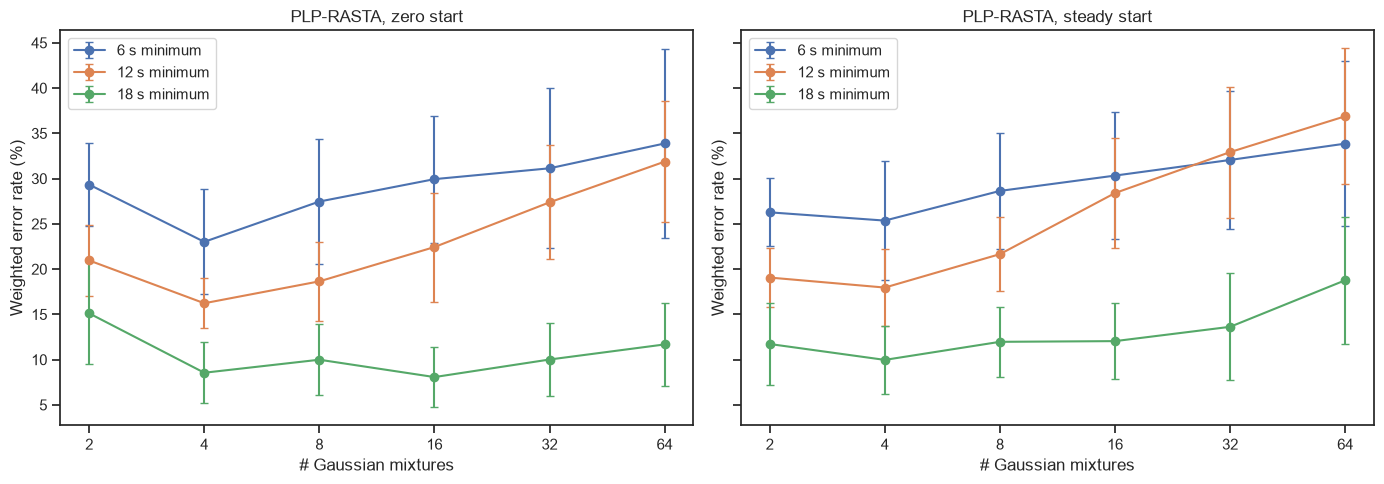

In [10]:
# Run Stage B for 6 s and 18 s, add the 12-second results of Stage A, and tabulate the grid.
per_species_b = pd.concat([
    per_species_a[per_species_a.feature.isin(STAGE_B_FEATURES)],
    run_grid(STAGE_B_FEATURES, "recording", tuple(t for t in TARGETS if t != STAGE_A_SECONDS)),
], ignore_index=True)
wer_b = wer_by_repeat(per_species_b)
assert len(wer_b) == len(STAGE_B_FEATURES) * len(TARGETS) * len(N_COMPONENTS_GRID) * N_REPEATS
print("conditions:", len(wer_b), "| fits:", len(per_species_b), "| converged:", int(per_species_b.converged.sum()))

summary_b = summarise(wer_b, ["feature", "training_seconds_target", "n_components"])
for name in STAGE_B_FEATURES:
    print("\n" + FEATURE_LABELS[name] + " - mean WER (%) by training minimum (rows) and number of Gaussians (columns):")
    display(summary_b[summary_b.feature == name].pivot(index="training_seconds_target", columns="n_components",
                                                        values="WER_mean").round(3))

fig, axes = plt.subplots(1, len(STAGE_B_FEATURES), figsize=(7 * len(STAGE_B_FEATURES), 5), sharey=True, squeeze=False)
for ax, name in zip(axes[0], STAGE_B_FEATURES):
    for target in TARGETS:
        sub = summary_b[(summary_b.feature == name) & (summary_b.training_seconds_target == target)].sort_values("n_components")
        ax.errorbar(sub.n_components, sub.WER_mean, yerr=sub.WER_std, marker="o", capsize=3, label=f"{target} s minimum")
    ax.set_xscale("log", base=2)
    ax.set_xticks(N_COMPONENTS_GRID)
    ax.set_xticklabels([str(m) for m in N_COMPONENTS_GRID])
    ax.set(title=FEATURE_LABELS[name], xlabel="# Gaussian mixtures", ylabel="Weighted error rate (%)")
    ax.legend()
plt.tight_layout()
plt.show()

`[OBSERVED]` All **3240 fits** of Stage B converged (180 conditions per RASTA start, with the 12-second ones taken from Stage A).

`[OBSERVED]` For the as-built PLP-RASTA, more training lowers the error at **every** model order: for example 29.334 %, 20.955 % and 15.113 % at M=2 for the 6, 12 and 18-second minimums, and 33.880 %, 31.871 % and 11.679 % at M=64.

`[OBSERVED]` With the 6 and 12-second minimums the error rises with the number of Gaussians beyond M=4. With the **18-second** minimum the curve is flat from M=4 to M=32 (8.552 %, 9.991 %, 8.073 %, 10.013 %) and rises only at M=64 (11.679 %), so more training data lets larger mixtures fit without losing accuracy.

`[OBSERVED]` The steady-start version behaves alike but is higher at larger orders: at the 18-second minimum 9.971 % at M=4 against 18.768 % at M=64.

## 11. The empirical best, and what cannot be told apart from it

**What this section asks, and why it matters.** Two selections are reported, as in the notebooks this one replaces:

1. the **empirical best**: the configuration (duration and number of Gaussians) with the lowest mean WER for the winning feature;
2. a **parsimonious recommendation**: the smallest number of Gaussians among the configurations whose mean WER is within one standard error of the best, and if several durations remain for that number, the lower
   mean WER and then the longer duration.

A complexity-aware rule is useful here because larger mixtures are clearly worse in Stage A. But the standard error is computed over ten splits that overlap (section 8), so it is **too small**, and the
rule must not be read as a statistical test. To show how much separates the candidates, every configuration is also compared with the best one split by split.

In [11]:
# Select the empirical best and the parsimonious recommendation, and compare every configuration with the best.
main = summary_b[summary_b.feature == ROBUST_FEATURE].copy()
best = main.sort_values(["WER_mean", "training_seconds_target", "n_components"]).iloc[0]
limit = best.WER_mean + best.WER_se
candidates = main[main.WER_mean <= limit].sort_values(["n_components", "WER_mean", "training_seconds_target"],
                                                       ascending=[True, True, False])
recommended = candidates.iloc[0]

print(f"empirical best        : {int(best.training_seconds_target)} s minimum, M={int(best.n_components)}, "
      f"WER {best.WER_mean:.3f}% (std {best.WER_std:.3f}, se {best.WER_se:.3f})")
print(f"one-standard-error limit: {limit:.3f}%")
print(f"configurations within the limit: {len(candidates)}")
display(candidates[["training_seconds_target", "n_components", "WER_mean", "WER_std", "WER_se"]].round(3))
print(f"recommended           : {int(recommended.training_seconds_target)} s minimum, M={int(recommended.n_components)}, "
      f"WER {recommended.WER_mean:.3f}% (std {recommended.WER_std:.3f})")

wide_b = wer_b[wer_b.feature == ROBUST_FEATURE].pivot_table(
    index=["training_seconds_target", "n_components"], columns="repeat", values="WER_percent")
best_key = (int(best.training_seconds_target), int(best.n_components))
paired_best = pd.DataFrame({
    "mean_diff_pp": (wide_b.sub(wide_b.loc[best_key], axis=1)).mean(axis=1),
    "std_diff_pp": (wide_b.sub(wide_b.loc[best_key], axis=1)).std(axis=1, ddof=1),
    "best_better_in": (wide_b.sub(wide_b.loc[best_key], axis=1) > 0).sum(axis=1),
}).sort_values("mean_diff_pp")
print("\nevery configuration minus the best one, split by split (percentage points); the 8 closest:")
display(paired_best.head(8).round(3))

empirical best        : 18 s minimum, M=16, WER 8.073% (std 3.341, se 1.057)
one-standard-error limit: 9.130%
configurations within the limit: 2


,training_seconds_target,n_components,WER_mean,WER_std,WER_se
13,18,4,8.552,3.376,1.068
15,18,16,8.073,3.341,1.057


recommended           : 18 s minimum, M=4, WER 8.552% (std 3.376)

every configuration minus the best one, split by split (percentage points); the 8 closest:


mean_diff_pp  std_diff_pp  best_better_in
training_seconds_target n_components                                           
18                      16                   0.000        0.000               0
                        4                    0.479        3.103               4
                        8                    1.918        2.332               9
                        32                   1.940        2.173               8
                        64                   3.606        2.868               9
                        2                    7.041        4.847               9
12                      4                    8.156        4.261               9
                        8                   10.576        5.386              10

`[OBSERVED]` The empirical best is **18 seconds and M=16**, at 8.073 % (standard deviation 3.341, standard error 1.057). The one-standard-error limit is 9.130 %, and **two** configurations lie within it: M=16 and **M=4 (8.552 %)**.
The parsimonious recommendation is therefore **18 seconds and M=4**.

`[OBSERVED]` Split by split, M=4 is only 0.479 points above the best, with a spread of 3.103, and the best is better in only 4 of 10 splits. M=8 and M=32 are about 1.9 points above the best (better in 9 and 8 of 10 splits), M=64 3.606 points above, and the best 12-second configuration is 8.156 points above.

`[OBSERVED]` The earlier notebook that this one replaces (its stored output, now archived), with the same splits but different random starts, found its empirical best at M=8 and recommended M=4. The empirical best has now moved to M=16 while the recommendation stayed at M=4.

`[INFERENCE]` M=4 and M=16 cannot be told apart, and the ranking among M=4 to M=32 at 18 seconds is not stable under a change of random starts. The recommendation of a small M rests on the parsimony rule, with the 12 and 6-second results where larger orders are clearly worse. It does not rest on the difference between 8.552 % and 8.073 %.
The standard errors used by the rule are too small (the splits overlap), so the rule is a convention for choosing among near-equals, not a test.

## 12. Per species, and how much training "18 seconds" really is

**What this section asks, and why it matters.** A macro-averaged error can hide species that fail, and a *minimum* duration can hide very different amounts of training. This section reports the error
of every species at the recommended configuration together with the training seconds and recordings it actually involved, and the training amount behind each minimum.

In [12]:
# Per-species behaviour of the recommended configuration, and the training amount behind each minimum duration.
rec = per_species_b[(per_species_b.feature == ROBUST_FEATURE)
                    & (per_species_b.training_seconds_target == recommended.training_seconds_target)
                    & (per_species_b.n_components == recommended.n_components)]
audit_rec = audit[audit.target == recommended.training_seconds_target]
per_species_rec = (rec.groupby(["code", "species"]).agg(error_mean=("error_rate", "mean"), error_std=("error_rate", "std"),
                                                         validation_calls=("n_validation_calls", "mean")).reset_index()
                   .assign(error_mean=lambda t: t.error_mean * 100, error_std=lambda t: t.error_std * 100)
                   .merge(audit_rec.groupby("code").agg(training_seconds=("training_seconds_actual", "mean"),
                                                         train_recordings=("n_train_recordings", "mean"),
                                                         validation_recordings=("n_validation_recordings", "mean")).reset_index(),
                          on="code"))
display(per_species_rec.round(2))

amount = audit.groupby("target").training_seconds_actual.agg(mean="mean", min="min", max="max")
amount["species_with_most"] = audit.loc[audit.groupby("target").training_seconds_actual.idxmax()].set_index("target").code
print("training seconds actually used per species, by minimum duration:")
display(amount.round(2))

,code,species,error_mean,error_std,validation_calls,training_seconds,train_recordings,validation_recordings
0,f01,Boana alfaroi,0.00,0.00,57.2,19.00,2.0,3.0
1,f02,Dendropsophus bifurcus,5.95,6.07,52.6,19.43,4.6,5.4
2,f03,Boana cinerascens,9.28,12.46,135.6,20.52,2.0,6.0
3,f04,Pristimantis conspicillatus,21.94,25.43,137.6,20.12,2.6,6.4
4,f05,Leptodactylus discodactylus,5.95,4.56,205.0,47.56,1.0,2.0
5,f06,Osteocephalus fuscifacies,0.00,0.00,12.9,18.72,3.8,1.2
6,f07,Boana lanciformis,27.18,27.58,64.5,20.92,2.8,4.2
7,f08,Rhinella margaritifera,6.59,14.41,72.3,21.78,2.1,4.9
8,f10,Engystomops petersi,0.08,0.25,264.2,22.28,2.5,9.5


training seconds actually used per species, by minimum duration:


,mean,min,max,species_with_most
target,,,,
6,8.47,6.00,15.50,f03
12,18.02,12.00,47.56,f05
18,23.37,18.02,47.56,f05


`[OBSERVED]` The macro error at the recommended configuration hides three groups. `f01`, `f06` and `f10` are essentially never wrong (0.00 %, 0.00 % and 0.08 %). `f02`, `f03`, `f05` and `f08` are between 5.95 % and 9.28 %.
**`f07` (27.18 %) and `f04` (21.94 %) fail often**, and their errors vary a lot between splits (standard deviations 27.58 and 25.43).

`[OBSERVED]` `f06` is validated on 1.2 recordings on average and `f05` on 2.0; `f05` is trained on a single recording of 47.56 seconds.

`[OBSERVED]` The "minimum" durations correspond to very different training amounts: on average **8.47 seconds** for the 6-second minimum, **18.02** for the 12-second one and **23.37** for the 18-second one, with a maximum of 47.56 seconds (`f05`) at the last two.

`[INFERENCE]` The 18-second minimum is both the largest duration tested and the one that gives most data and most recordings, so the experiment shows that more training helps but not where it would stop helping. The duration in the exported file is a minimum used in this experiment and not a rule to discard data.

## 13. Is the choice of RASTA start decided?

**What this section asks, and why it matters.** The detector will be built on one of the two PLP-RASTA starts, so the choice has to be made from the numbers and stated. Stage B ran both, so they can
be compared at every duration and model order, split by split.

In [13]:
# Compare the two RASTA starts at every duration and model order, on identical splits.
if OTHER_START is None:
    print("only one RASTA start was carried to Stage B")
else:
    wide_s = wer_b.pivot_table(index=["training_seconds_target", "n_components", "repeat"], columns="feature", values="WER_percent")
    diff = (wide_s[OTHER_START] - wide_s[ROBUST_FEATURE]).unstack("repeat")
    start_table = pd.DataFrame({
        "mean_diff_pp": diff.mean(axis=1), "std_diff_pp": diff.std(axis=1, ddof=1),
        "winner_better_in": (diff > 0).sum(axis=1)})
    print(f"{FEATURE_LABELS[OTHER_START]} minus {FEATURE_LABELS[ROBUST_FEATURE]} (pp); winner_better_in counts splits of {N_REPEATS}:")
    display(start_table.round(2).unstack("n_components").swaplevel(axis=1).sort_index(axis=1))
    print("configurations in which the winner is better on average:", int((start_table.mean_diff_pp > 0).sum()), "of", len(start_table))

PLP-RASTA, steady start minus PLP-RASTA, zero start (pp); winner_better_in counts splits of 10:


n_components                      2                                         4                                         8                                         16              \
                        mean_diff_pp std_diff_pp winner_better_in mean_diff_pp std_diff_pp winner_better_in mean_diff_pp std_diff_pp winner_better_in mean_diff_pp std_diff_pp   
training_seconds_target                                                                                                                                                          
6                              -3.06        2.82                1         2.35        3.02                8         1.17        2.03                7         0.39        2.84   
12                             -1.89        2.04                2         1.73        3.44                7         3.01        3.84                9         5.97        2.57   
18                             -3.39        3.76                3         1.42        3.55                7         1.98        2.78                8         3.97        2.71   

n_components                                       32                                        64                               
                        winner_better_in mean_diff_pp std_diff_pp winner_better_in mean_diff_pp std_diff_pp winner_better_in  
training_seconds_target                                                                                                       
6                                      5         0.92        4.18                7        -0.02        3.50                6  
12                                    10         5.55        2.36               10         5.01        2.92               10  
18                                     9         3.61        4.89                8         7.09        5.62                9

configurations in which the winner is better on average: 14 of 18


`[OBSERVED]` The as-built (zero) start is better on average in **14 of the 18** duration and model-order combinations. The steady start is better at M=2 for every duration (3.06, 1.89 and 3.39 points).

`[OBSERVED]` At the recommended M=4 the as-built start is better by 2.35, 1.73 and 1.42 points for the 6, 12 and 18-second minimums, with spreads of 3.02, 3.44 and 3.55, and in 7 or 8 of 10 splits. At M=16 to M=64 with the 12 and 18-second minimums it is better by 3.61 to 7.09 points in 8 to 10 of the 10 splits.

`[INFERENCE]` At the model order that is recommended the two starts are close and not separable with ten splits, so the choice of the start does not decide the recommendation. At larger orders the zero start is clearly better.
It is the version that the stored features, and everything computed from them, already use, so it is retained as the primary feature. The reason why it generalises better, in a protocol where the start-up transient (notebook 04) cannot
come from a shared recording, is not determined here.

## 14. Export the selected configuration

**What this section asks, and why it matters.** The detector stage must not guess what won here, so the selection is written to a file it reads. The file keeps the keys the detector already reads
(`recommended_parsimonious` with `n_components` and `training_seconds_target`), and records the feature, which RASTA start it is, the validation rule and what limits the result.

*The training duration in the file is a minimum target used in this experiment, not an instruction to discard labelled data.* A deployed model may use all the material available.

In [14]:
# Write the selection file and the experiment tables, reload the file, and list only what this notebook wrote.
rasta_start = {"20_PLP_RASTA": "zero", "PLP_steady": "steady", "PLP_no_rasta": None}.get(ROBUST_FEATURE)
alternative = (summary_b[summary_b.feature == OTHER_START].sort_values(["WER_mean", "training_seconds_target", "n_components"]).iloc[0]
               if OTHER_START else None)

selection = {
    "selection_notebook": "05_model_selection",
    "validation_unit": "source_wav",
    "group_column": "wav",
    "feature": ROBUST_FEATURE,
    "feature_dimensions": 20,
    "rasta_start": rasta_start,
    "classes": list(USABLE_CODES),
    "excluded_class": "f09",
    "n_repeats": N_REPEATS,
    "feature_comparison_target_seconds": STAGE_A_SECONDS,
    "training_targets_tested": list(TARGETS),
    "n_components_tested": list(N_COMPONENTS_GRID),
    "empirical_best": {"training_seconds_target": int(best.training_seconds_target), "n_components": int(best.n_components),
                       "WER_mean": float(best.WER_mean) / 100, "WER_std": float(best.WER_std) / 100, "WER_se": float(best.WER_se) / 100},
    "recommended_parsimonious": {"training_seconds_target": int(recommended.training_seconds_target),
                                 "n_components": int(recommended.n_components),
                                 "WER_mean": float(recommended.WER_mean) / 100, "WER_std": float(recommended.WER_std) / 100,
                                 "selection_rule": "smallest M within one standard error of the empirical minimum"},
    "other_rasta_start": None if alternative is None else {
        "feature": OTHER_START, "best_training_seconds_target": int(alternative.training_seconds_target),
        "best_n_components": int(alternative.n_components), "best_WER_mean": float(alternative.WER_mean) / 100},
    "paper_reference": {"feature": "20_mFCC", "n_components": 64,
                        "note": "published result, kept as the reference and not forced onto the recovered-data model"},
    "limitations": [
        "training seconds are minimum targets because whole recordings are assigned together",
        "the ten splits share recordings, so standard errors are too small and are not a statistical test",
        "PLP-RASTA and m-FCC are reconstructions, and the article does not say how its RASTA filter started",
        "some species have few recordings, so their held-out error is based on one or two recordings",
    ],
}
SELECTION_PATH = RESULTS_DIR / "selected_robust_configuration.json"
SELECTION_PATH.write_text(json.dumps(selection, indent=2), encoding="utf-8")
reloaded = json.loads(SELECTION_PATH.read_text(encoding="utf-8"))
print("selection file reloads identically:", reloaded == selection)
print(json.dumps({k: reloaded[k] for k in ("feature", "rasta_start", "recommended_parsimonious")}, indent=2))

OUTPUTS = {
    "split_audit.csv": audit, "call_vs_recording_wer_by_repeat.csv": wer_leak,
    "stage_a_wer_by_repeat.csv": wer_a, "stage_a_summary.csv": summary_a, "stage_a_paired_differences.csv": paired_a,
    "stage_b_wer_by_repeat.csv": wer_b, "stage_b_summary.csv": summary_b, "stage_b_per_species.csv": per_species_b,
    "recommended_per_species.csv": per_species_rec, "paired_to_best.csv": paired_best.reset_index(),
}
for name, table in OUTPUTS.items():
    table.to_csv(RESULTS_DIR / name, index=False)

print("\nwritten to", RESULTS_DIR.relative_to(REPO_ROOT).as_posix())
for name in ["selected_robust_configuration.json", *OUTPUTS]:
    print(f"  {name:<40} {(RESULTS_DIR / name).stat().st_size / 1e6:>7.3f} MB")

selection file reloads identically: True
{
  "feature": "20_PLP_RASTA",
  "rasta_start": "zero",
  "recommended_parsimonious": {
    "training_seconds_target": 18,
    "n_components": 4,
    "WER_mean": 0.08552013749502484,
    "WER_std": 0.033760757196778804,
    "selection_rule": "smallest M within one standard error of the empirical minimum"
  }
}

written to data/processed/robust_model_selection
  selected_robust_configuration.json         0.002 MB
  split_audit.csv                            0.024 MB
  call_vs_recording_wer_by_repeat.csv        0.011 MB
  stage_a_wer_by_repeat.csv                  0.017 MB
  stage_a_summary.csv                        0.004 MB
  stage_a_paired_differences.csv             0.002 MB
  stage_b_wer_by_repeat.csv                  0.018 MB
  stage_b_summary.csv                        0.004 MB
  stage_b_per_species.csv                    0.363 MB
  recommended_per_species.csv                0.001 MB
  paired_to_best.csv                         0.001 MB


`[OBSERVED]` The selection file reloads identically and records the feature `20_PLP_RASTA`, the zero start, and the recommended **18-second minimum with M=4**. It keeps the keys the detector reads, and adds the alternative start and the limitations.

## 15. Conclusions and limitations

**What this notebook delivers.** The choice of feature set and model order under a validation that keeps whole recordings apart, which is the situation of the testing stage. It replaces two earlier notebooks, one that selected under the
article's call-level protocol and one that repeated the selection with recordings kept apart. The split search is in `frog_presence.gmm` with tests, and takes seconds where the earlier version took minutes.
The selection is written to `data/processed/robust_model_selection/selected_robust_configuration.json`.

**What was found.**

1. **The article's protocol and a recording-level one disagree by an order of magnitude.** For PLP-RASTA the error is 0.235 % to 2.370 % with calls split at random and 16.229 % to 31.871 % with recordings kept apart; the model order that wins also changes.
2. **PLP-RASTA wins clearly.** It is better than every feature set without RASTA in 10 of 10 splits at every model order, by 13.42 to 29.23 points. The article's m-FCC does no better than standard MFCC here.
3. **A small number of Gaussians is best.** M=4 for 6 and 12 seconds, and M=4 to M=32 are not separable at 18 seconds, where the recommendation is M=4.
4. **The choice between the two RASTA starts is not decided at M=4** (a difference of 1.42 to 2.35 points with spreads of about 3), and the zero start is clearly better at larger orders. It is retained.
5. **The configuration is weak for two species.** `f07` errs 27.18 % and `f04` 21.94 % at the recommended setting.

**Decisions taken here, which the article does not state.**

1. **The split is global and by recording**, with the smallest-overshoot assignment among many random ones, so the training durations are minimums.
2. **The rule for the feature**: the lowest best mean WER over the model orders, applied before the numbers were seen; both RASTA starts are carried to Stage B.
3. **The parsimony rule**: the smallest number of Gaussians within one standard error of the best, then the lower error and the longer duration.
4. **The exported feature is the as-built PLP-RASTA**, which the stored per-call features use.

**Limitations.**

- **The ten splits overlap**, being drawn from the same 66 recordings, so standard errors are too small and nothing here is a statistical test.
- **Duration and recordings are confounded**: a longer minimum also brings more recordings, and `f05` always trains on one recording.
- **Some species have one or two validation recordings** (`f05`, `f06`), so their errors are noisy.
- **Both PLP-RASTA starts and the m-FCC are reconstructions**, and the article does not say how its RASTA filter started.
- **M=4 and M=16 cannot be told apart**; the recommendation rests on parsimony.
- **The ranking among model orders depends on the random starts**, as the move of the empirical best from M=8 to M=16 shows.

**What the next stage inherits.** The detector built on this selection uses the zero-start PLP-RASTA with 4 Gaussians per species. Its measured accuracy on unseen recordings is that of this notebook (about 8.5 % WER, with `f07` and `f04` weak), not the sub-percent figures of
the article's protocol.